In [68]:
from google.colab import files

uploaded = files.upload()

Saving RealEstate_Prices.csv to RealEstate_Prices.csv


In [69]:
import pandas as pd

# 1. Create and load
data = {
'Property ID': ['P001', 'P002', 'P003', 'P004', 'P005', 'P006', 'P007'],
'Location': ['Pune', 'Mumbai', 'Pune', 'Delhi', 'Mumbai', 'Pune', 'Delhi'],
'Property Type': ['Apartment', 'House', 'Apartment', 'House', 'Apartment', 'House', 'Apartment'],
'Area (sqft)': [1200, 1800, 1000, 2000, 900, None, 1100],
'Bedrooms': [2, 3, 2, 4, 2, 3, 2],
'Price': [6000000, 12000000, 5000000, 15000000, 7000000, 9000000, 100000000]
}
df = pd.DataFrame(data)
df.to_csv('RealEstate_Prices.csv', index=False)
df = pd.read_csv('RealEstate_Prices.csv')
print("Dataset loaded!")
display(df)

# 2. Clean column names and handle missing
df.columns = df.columns.str.replace(' ', '_')
df.columns = df.columns.str.replace(r'[()]', '', regex=True)
df['Area_sqft'] = df['Area_sqft'].fillna(df['Area_sqft'].mean())
print("Cleaned:")
display(df)

# 3. Data Merging
neighborhood = pd.DataFrame({
'Location': ['Pune', 'Mumbai', 'Delhi'],
'Amenities': ['High', 'High', 'Medium']
})
df = pd.merge(df, neighborhood, on='Location')
print("After Merging:")
display(df)

# 4. Filter
pune_data = df[df['Location'] == 'Pune']
print("Pune Properties:")
display(pune_data)

# 5. Encode
encoded_df = pd.get_dummies(df, columns=['Location', 'Property_Type', 'Amenities'])
print("Encoded:")
display(encoded_df)

# 6. Aggregate
print("Avg Price by Location:")
print(df.groupby('Location')['Price'].mean())
print("\nAvg Price by Property Type:")
print(df.groupby('Property_Type')['Price'].mean())

# 7. Outliers
Q1 = df['Price'].quantile(0.25)
Q3 = df['Price'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
df_clean = df[(df['Price'] >= lower) & (df['Price'] <= upper)]
print("After removing outliers:")
display(df_clean)

Dataset loaded!


,Property ID,Location,Property Type,Area (sqft),Bedrooms,Price
0,P001,Pune,Apartment,1200.0,2,6000000
1,P002,Mumbai,House,1800.0,3,12000000
2,P003,Pune,Apartment,1000.0,2,5000000
3,P004,Delhi,House,2000.0,4,15000000
4,P005,Mumbai,Apartment,900.0,2,7000000
5,P006,Pune,House,NaN,3,9000000
6,P007,Delhi,Apartment,1100.0,2,100000000


Cleaned:


,Property_ID,Location,Property_Type,Area_sqft,Bedrooms,Price
0,P001,Pune,Apartment,1200.000000,2,6000000
1,P002,Mumbai,House,1800.000000,3,12000000
2,P003,Pune,Apartment,1000.000000,2,5000000
3,P004,Delhi,House,2000.000000,4,15000000
4,P005,Mumbai,Apartment,900.000000,2,7000000
5,P006,Pune,House,1333.333333,3,9000000
6,P007,Delhi,Apartment,1100.000000,2,100000000


After Merging:


,Property_ID,Location,Property_Type,Area_sqft,Bedrooms,Price,Amenities
0,P001,Pune,Apartment,1200.000000,2,6000000,High
1,P002,Mumbai,House,1800.000000,3,12000000,High
2,P003,Pune,Apartment,1000.000000,2,5000000,High
3,P004,Delhi,House,2000.000000,4,15000000,Medium
4,P005,Mumbai,Apartment,900.000000,2,7000000,High
5,P006,Pune,House,1333.333333,3,9000000,High
6,P007,Delhi,Apartment,1100.000000,2,100000000,Medium


... (2 outputs left out)

Encoded:


,Property_ID,Area_sqft,Bedrooms,Price,Location_Delhi,Location_Mumbai,Location_Pune,Property_Type_Apartment,Property_Type_House,Amenities_High,Amenities_Medium
0,P001,1200.000000,2,6000000,False,False,True,True,False,True,False
1,P002,1800.000000,3,12000000,False,True,False,False,True,True,False
2,P003,1000.000000,2,5000000,False,False,True,True,False,True,False
3,P004,2000.000000,4,15000000,True,False,False,False,True,False,True
4,P005,900.000000,2,7000000,False,True,False,True,False,True,False
5,P006,1333.333333,3,9000000,False,False,True,False,True,True,False
6,P007,1100.000000,2,100000000,True,False,False,True,False,False,True


Avg Price by Location:
Location
Delhi     5.750000e+07
Mumbai    9.500000e+06
Pune      6.666667e+06
Name: Price, dtype: float64

Avg Price by Property Type:
Property_Type
Apartment    29500000.0
House        12000000.0
Name: Price, dtype: float64
After removing outliers:


,Property_ID,Location,Property_Type,Area_sqft,Bedrooms,Price,Amenities
0,P001,Pune,Apartment,1200.000000,2,6000000,High
1,P002,Mumbai,House,1800.000000,3,12000000,High
2,P003,Pune,Apartment,1000.000000,2,5000000,High
3,P004,Delhi,House,2000.000000,4,15000000,Medium
4,P005,Mumbai,Apartment,900.000000,2,7000000,High
5,P006,Pune,House,1333.333333,3,9000000,High


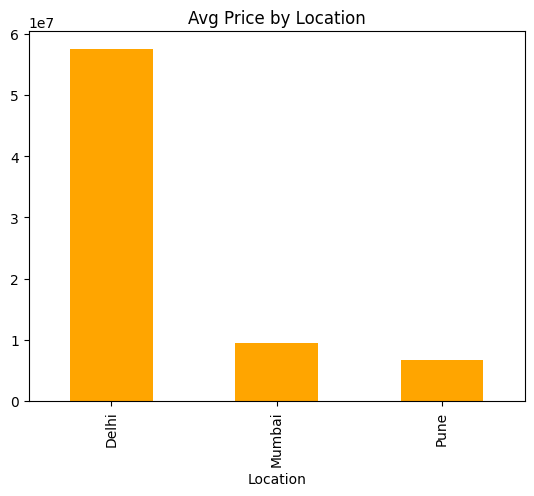

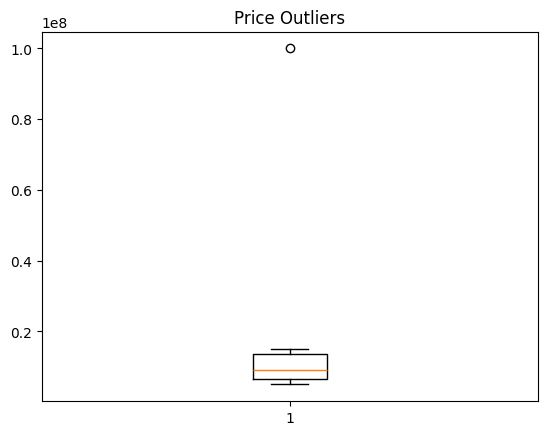

In [70]:
import matplotlib.pyplot as plt

# Plot 1: Avg Price by Location
plt.figure()
df.groupby('Location')['Price'].mean().plot(kind='bar', color='orange')
plt.title('Avg Price by Location')
plt.show()

# Plot 2: Price Boxplot for Outlier
plt.figure()
plt.boxplot(df['Price'])
plt.title('Price Outliers')
plt.show()

In [71]:
# Save
from google.colab import files
df_clean.to_csv('Cleaned_RealEstate_Prices.csv', index=False)
files.download("Cleaned_RealEstate_Prices.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>